# Pandas

The `numpy` module is excellent for numerical computations, but to handle missing data or arrays with mixed types takes more work. The `pandas` module is currently the most widely used tool for data manipulation, providing high-performance, easy-to-use data structures and advanced data analysis tools.

In particular `pandas` features:

* A fast and efficient "DataFrame" object for data manipulation with integrated indexing;
* Tools for reading and writing data between in-memory data structures and different formats (CSV, Excel, SQL, HDF5);
* Intelligent data alignment and integrated handling of missing data;
* Intelligent label-based slicing, fancy indexing, and subsetting of large data sets;
* Aggregating or transforming data with a powerful "group-by" engine; 
* High performance merging and joining of data sets;
* Hierarchical axis indexing provides an intuitive way of working with high-dimensional data in a lower-dimensional data structure;
* Time series-functionalities;
* Highly optimized for performance, with critical code paths written in Cython or C.


In [1]:
import pandas as pd
import numpy as np

## Series

Series are completely equivalent to 1D array but with axis labels and the possibility to store heterogeneous elements. Of paramount importance are the time-series, used to define time evolutions of a phenomenon. 


In [2]:
from string import ascii_lowercase as letters

# Creating a series, accessing indexes, values and values by their index 
xs = pd.Series(np.arange(10)*0.5, index=tuple(letters[:10])) # a cada valor le asigno un index
print ("xs:", xs,'\n')
print ("xs indexes:",xs.index,'\n')
# Values of the Series are actually a numpy array
print ("xs values:", xs.values, type(xs.values),'\n')
print (xs['f'], xs.f, xs.h, '\n')
print (xs[['d', 'f', 'h']], '\n')
print (type(xs[['d', 'f', 'h']]), '\n')

xs: a    0.0
b    0.5
c    1.0
d    1.5
e    2.0
f    2.5
g    3.0
h    3.5
i    4.0
j    4.5
dtype: float64 

xs indexes: Index(['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j'], dtype='object') 

xs values: [0.  0.5 1.  1.5 2.  2.5 3.  3.5 4.  4.5] <class 'numpy.ndarray'> 

2.5 2.5 3.5 

d    1.5
f    2.5
h    3.5
dtype: float64 

<class 'pandas.core.series.Series'> 



In [3]:
# Extracting elements and operations: same as numpy array
print (xs[:3],'\n')
print (xs[7:], '\n')
print (xs[::3], '\n')# sacar cda tecer elemento del array
print (xs[xs>3], '\n')
print (np.exp(xs), '\n')
print (np.mean(xs), np.std(xs), '\n')

a    0.0
b    0.5
c    1.0
dtype: float64 

h    3.5
i    4.0
j    4.5
dtype: float64 

a    0.0
d    1.5
g    3.0
j    4.5
dtype: float64 

h    3.5
i    4.0
j    4.5
dtype: float64 

a     1.000000
b     1.648721
c     2.718282
d     4.481689
e     7.389056
f    12.182494
g    20.085537
h    33.115452
i    54.598150
j    90.017131
dtype: float64 

2.25 1.4361406616345072 



In [4]:
# Series can be created from python dictionary too.
# Not that the elements can be whatever!
d = {'b' : 1, 'a' : 'cat', 'c' : [2,3]}
pd.Series(d)



b         1
a       cat
c    [2, 3]
dtype: object

A key difference between Series and ndarray is that operations between Series automatically align the data based on label. Thus, you can write computations without considering whether the Series involved have the same labels.

In [5]:
s = pd.Series(np.random.randn(5), index=tuple(letters[:5]))
print(s)
s = s[1:] + s[:-1]
print(s)

a    0.730822
b   -0.299199
c    0.917372
d   -1.685719
e   -0.901884
dtype: float64
a         NaN
b   -0.598399
c    1.834744
d   -3.371439
e         NaN
dtype: float64


### Time series

Time series are very often used to profile the behaviour of a quantity as a function of time. Pandas has a special index for that, `DatetimeIndex`, that can be created e.g. with the function `pd.data_range()`

In [13]:
# to define a date, the datetime module is very useful
import datetime as dt
date = dt.date.today() # meant to be indexes of a series
print(date)

date = dt.datetime(2026,11,18,10,45,10,15)
print (date)

# otherwise, several notations are interpreted too
date = 'Nov 18 2026'
# or alternatively
#date = '18/11/2026 10:45:00'
print (date)

days = pd.date_range(date, periods=7, freq='D') # D stands for days
print (days)

seconds = pd.date_range(date, periods=3600, freq='s')
print (seconds)


2026-11-18
2026-11-18 10:45:10.000015
Nov 18 2026
DatetimeIndex(['2026-11-18', '2026-11-19', '2026-11-20', '2026-11-21',
               '2026-11-22', '2026-11-23', '2026-11-24'],
              dtype='datetime64[ns]', freq='D')
DatetimeIndex(['2026-11-18 00:00:00', '2026-11-18 00:00:01',
               '2026-11-18 00:00:02', '2026-11-18 00:00:03',
               '2026-11-18 00:00:04', '2026-11-18 00:00:05',
               '2026-11-18 00:00:06', '2026-11-18 00:00:07',
               '2026-11-18 00:00:08', '2026-11-18 00:00:09',
               ...
               '2026-11-18 00:59:50', '2026-11-18 00:59:51',
               '2026-11-18 00:59:52', '2026-11-18 00:59:53',
               '2026-11-18 00:59:54', '2026-11-18 00:59:55',
               '2026-11-18 00:59:56', '2026-11-18 00:59:57',
               '2026-11-18 00:59:58', '2026-11-18 00:59:59'],
              dtype='datetime64[ns]', length=3600, freq='S')


To learn more about the frequency strings, please see this [link](http://pandas.pydata.org/pandas-docs/stable/timeseries.html#offset-aliases)


Timestamped data is the most basic type of time series data that associates values with points in time. For pandas objects it means using the points in time.

functions like `pd.to_datetime` can be used, for instance, when reading information as string from a dataset.

Timestamp is the pandas equivalent of python’s Datetime and is interchangeable with it in most cases. 

In [14]:
tstamp = pd.Timestamp(dt.datetime(2020, 11, 9))

# internally it counts the nanoseconds from January 1st 19
#tstamp = pd.Timestamp(dt.datetime(1970, 1, 1, 0, 0, 0, 1))
print(tstamp.value)

# when creating a timestamp the format can be explicitly passed
ts = pd.to_datetime('2010/11/12', format='%Y/%m/%d')
print (type(ts))
print (ts.value)
ts = pd.to_datetime('12-11-2010 00:00', format='%d-%m-%Y %H:%M')
print (ts)
print (ts.value)



1604880000000000000
<class 'pandas._libs.tslibs.timestamps.Timestamp'>
1289520000000000000
2010-11-12 00:00:00
1289520000000000000


A standard series can be created and (range of) elements can be used as indexes

In [15]:
tseries = pd.Series(np.random.normal(10, 1, len(days)), index=days)
# Extracting elements
print (tseries[0:4], '\n')
print (tseries['2026-11-18':'2026-12-01'], '\n') # Note - includes end time


2026-11-18    8.584927
2026-11-19    8.943160
2026-11-20    9.800189
2026-11-21    9.883450
Freq: D, dtype: float64 

2026-11-18     8.584927
2026-11-19     8.943160
2026-11-20     9.800189
2026-11-21     9.883450
2026-11-22    10.416851
2026-11-23     9.734599
2026-11-24    10.301093
Freq: D, dtype: float64 



`pd.to_datetime` can also be used to create a `DatetimeIndex`:

In [ ]:
pd.to_datetime([1, 2, 3, 4], unit='D', origin=pd.Timestamp('1980-02-03'))

## DataFrame

A pandas DataFrame is like a simple tabular spreadsheet. For future reference (or for people already familiar with R), a pandas DataFrame is very similar to the R DataFrame.

Each column in a DataFrame is a Series object.

The element can be whatever, missing data are dealt with too (as NaN)

### DataFrame creation

A DataFrame can be created implicitly, with, e.g., a DatatimeIndex object as index:

In [17]:
# like stacked series
entries=10
dates=pd.date_range('11/18/2026 10:45:00',freq='h', periods=entries)
df = pd.DataFrame(np.random.randn(entries,4), index=dates, columns=['A','B','C','D'])
df


,A,B,C,D
2026-11-18 10:45:00,0.457652,0.667562,0.435262,0.566280
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,-0.962187
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,-1.304426
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,-0.928649
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,1.812903
2026-11-18 15:45:00,0.731377,0.529201,0.860164,-1.851711
2026-11-18 16:45:00,0.548651,0.695225,1.229221,0.985750
2026-11-18 17:45:00,0.775679,0.219728,1.449810,1.227008
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,0.959595
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,0.816221


or by means of a dictionary:


In [20]:
df2 = pd.DataFrame(
    { 'A' : 1.,
      'B' : pd.Timestamp('20130102'),
      'C' : pd.Series(1,index=range(4),dtype='float32'),
      'D' : np.arange(7,11),
      'E' : pd.Categorical(["test","train","test","train"]),
    }
    )
df2

# check what happens if D and E had different lenghts 
# does not work

,A,B,C,D,E
0,1.0,2013-01-02,1.0,7,test
1,1.0,2013-01-02,1.0,8,train
2,1.0,2013-01-02,1.0,9,test
3,1.0,2013-01-02,1.0,10,train


### Viewing Data

In [21]:
df.head()

,A,B,C,D
2026-11-18 10:45:00,0.457652,0.667562,0.435262,0.566280
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,-0.962187
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,-1.304426
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,-0.928649
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,1.812903


In [22]:
df.tail(4)

,A,B,C,D
2026-11-18 16:45:00,0.548651,0.695225,1.229221,0.985750
2026-11-18 17:45:00,0.775679,0.219728,1.449810,1.227008
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,0.959595
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,0.816221


In [23]:
df.index

DatetimeIndex(['2026-11-18 10:45:00', '2026-11-18 11:45:00',
               '2026-11-18 12:45:00', '2026-11-18 13:45:00',
               '2026-11-18 14:45:00', '2026-11-18 15:45:00',
               '2026-11-18 16:45:00', '2026-11-18 17:45:00',
               '2026-11-18 18:45:00', '2026-11-18 19:45:00'],
              dtype='datetime64[ns]', freq='H')

In [24]:
df.columns

Index(['A', 'B', 'C', 'D'], dtype='object')

In [25]:
df.values

array([[ 0.45765217,  0.66756239,  0.43526207,  0.56628034],
       [-1.59281034,  1.15282109,  0.15802135, -0.96218682],
       [ 0.0754196 , -0.79704942,  0.60447268, -1.30442622],
       [ 0.63136019, -0.17382307, -0.92950631, -0.92864915],
       [-1.03111822, -0.53583787,  0.80803105,  1.81290301],
       [ 0.73137678,  0.52920107,  0.86016411, -1.85171056],
       [ 0.54865063,  0.69522496,  1.2292213 ,  0.98574991],
       [ 0.77567915,  0.21972752,  1.44980979,  1.22700812],
       [ 0.9955024 , -0.947823  ,  0.14462921,  0.95959549],
       [ 0.10146839,  1.64980312, -0.18848628,  0.81622077]])

In [26]:
df.describe()

,A,B,C,D
count,10.000000,10.000000,10.000000,10.000000
mean,0.169318,0.245981,0.457162,0.132078
std,0.841047,0.853365,0.700476,1.265600
min,-1.592810,-0.947823,-0.929506,-1.851711
25%,0.081932,-0.445334,0.147977,-0.953802
50%,0.503151,0.374464,0.519867,0.691251
75%,0.706373,0.688309,0.847131,0.979211
max,0.995502,1.649803,1.449810,1.812903


In [27]:
df.T

,2026-11-18 10:45:00,2026-11-18 11:45:00,2026-11-18 12:45:00,2026-11-18 13:45:00,2026-11-18 14:45:00,2026-11-18 15:45:00,2026-11-18 16:45:00,2026-11-18 17:45:00,2026-11-18 18:45:00,2026-11-18 19:45:00
A,0.457652,-1.592810,0.075420,0.631360,-1.031118,0.731377,0.548651,0.775679,0.995502,0.101468
B,0.667562,1.152821,-0.797049,-0.173823,-0.535838,0.529201,0.695225,0.219728,-0.947823,1.649803
C,0.435262,0.158021,0.604473,-0.929506,0.808031,0.860164,1.229221,1.449810,0.144629,-0.188486
D,0.566280,-0.962187,-1.304426,-0.928649,1.812903,-1.851711,0.985750,1.227008,0.959595,0.816221


In [28]:
df.sort_index(axis=0,ascending=False)

,A,B,C,D
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,0.816221
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,0.959595
2026-11-18 17:45:00,0.775679,0.219728,1.449810,1.227008
2026-11-18 16:45:00,0.548651,0.695225,1.229221,0.985750
2026-11-18 15:45:00,0.731377,0.529201,0.860164,-1.851711
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,1.812903
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,-0.928649
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,-1.304426
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,-0.962187
2026-11-18 10:45:00,0.457652,0.667562,0.435262,0.566280


In [29]:
df.sort_values(by="C") # we are sorting C from lower to larger values, the other of the other also align wtih C order

,A,B,C,D
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,-0.928649
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,0.816221
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,0.959595
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,-0.962187
2026-11-18 10:45:00,0.457652,0.667562,0.435262,0.566280
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,-1.304426
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,1.812903
2026-11-18 15:45:00,0.731377,0.529201,0.860164,-1.851711
2026-11-18 16:45:00,0.548651,0.695225,1.229221,0.985750
2026-11-18 17:45:00,0.775679,0.219728,1.449810,1.227008


## Selection

### Getting slices

The following show how to get part of the DataFrame (i.e. not just the elements)

In [30]:
## standard and safe
print (df['A'],'\n')

## equivalent but dangerous (imagine blank spaces in the name of the column..)
print (df.A)

2026-11-18 10:45:00    0.457652
2026-11-18 11:45:00   -1.592810
2026-11-18 12:45:00    0.075420
2026-11-18 13:45:00    0.631360
2026-11-18 14:45:00   -1.031118
2026-11-18 15:45:00    0.731377
2026-11-18 16:45:00    0.548651
2026-11-18 17:45:00    0.775679
2026-11-18 18:45:00    0.995502
2026-11-18 19:45:00    0.101468
Freq: H, Name: A, dtype: float64 

2026-11-18 10:45:00    0.457652
2026-11-18 11:45:00   -1.592810
2026-11-18 12:45:00    0.075420
2026-11-18 13:45:00    0.631360
2026-11-18 14:45:00   -1.031118
2026-11-18 15:45:00    0.731377
2026-11-18 16:45:00    0.548651
2026-11-18 17:45:00    0.775679
2026-11-18 18:45:00    0.995502
2026-11-18 19:45:00    0.101468
Freq: H, Name: A, dtype: float64


In [33]:
# selecting rows by counting
print (df[0:3])

# or by index
print (df["2026-11-18 10:45:00":"2026-11-18 12:45:00"])

                            A         B         C         D
2026-11-18 10:45:00  0.457652  0.667562  0.435262  0.566280
2026-11-18 11:45:00 -1.592810  1.152821  0.158021 -0.962187
2026-11-18 12:45:00  0.075420 -0.797049  0.604473 -1.304426
                            A         B         C         D
2026-11-18 10:45:00  0.457652  0.667562  0.435262  0.566280
2026-11-18 11:45:00 -1.592810  1.152821  0.158021 -0.962187
2026-11-18 12:45:00  0.075420 -0.797049  0.604473 -1.304426


### Selection by label

In [34]:
# getting a cross section (part of the DataFrame) using a label
df.loc[dates[0]] # firswt entry (fisrt row)

A    0.457652
B    0.667562
C    0.435262
D    0.566280
Name: 2026-11-18 10:45:00, dtype: float64

In [35]:
# selecting on a multi-axis by label:
df.loc[:"2026-11-18 12:45:00",['A','B']] # select sections, first three rows for A and B
#a=df.loc[:,['A','B']]

,A,B
2026-11-18 10:45:00,0.457652,0.667562
2026-11-18 11:45:00,-1.592810,1.152821
2026-11-18 12:45:00,0.075420,-0.797049


In [36]:
# showing label slicing, both endpoints are included:
df.loc['2026-11-18 14:45:00':'2026-11-18 16:45:00',['A','B']]

,A,B
2026-11-18 14:45:00,-1.031118,-0.535838
2026-11-18 15:45:00,0.731377,0.529201
2026-11-18 16:45:00,0.548651,0.695225


In [37]:
# getting an individual element
print (df.loc[dates[1],'A'])

# equivalently
print (df.at[dates[1],'A'])

-1.5928103415611163
-1.5928103415611163


### Selecting by position

In [38]:
#ignore the name of the index and the name of the columns
# select via the position of the passed integers:
print (df.iloc[3],'\n')

# notation similar to numpy/python
print (df.iloc[3:5,0:2])

A    0.631360
B   -0.173823
C   -0.929506
D   -0.928649
Name: 2026-11-18 13:45:00, dtype: float64 

                            A         B
2026-11-18 13:45:00  0.631360 -0.173823
2026-11-18 14:45:00 -1.031118 -0.535838


In [39]:
# selecting rows 1,2 and 4 for columns 0 and 2
df.iloc[[1,2,4],[0,2]]

,A,C
2026-11-18 11:45:00,-1.592810,0.158021
2026-11-18 12:45:00,0.075420,0.604473
2026-11-18 14:45:00,-1.031118,0.808031


In [40]:
# slicing rows explicitly
print (df.iloc[1:3,:],'\n')

# slicing columns explicitly
print (df.iloc[:,1:3])

# selecting an individual element by position
print(df.iloc[1,1])

                           A         B         C         D
2026-11-18 11:45:00 -1.59281  1.152821  0.158021 -0.962187
2026-11-18 12:45:00  0.07542 -0.797049  0.604473 -1.304426 

                            B         C
2026-11-18 10:45:00  0.667562  0.435262
2026-11-18 11:45:00  1.152821  0.158021
2026-11-18 12:45:00 -0.797049  0.604473
2026-11-18 13:45:00 -0.173823 -0.929506
2026-11-18 14:45:00 -0.535838  0.808031
2026-11-18 15:45:00  0.529201  0.860164
2026-11-18 16:45:00  0.695225  1.229221
2026-11-18 17:45:00  0.219728  1.449810
2026-11-18 18:45:00 -0.947823  0.144629
2026-11-18 19:45:00  1.649803 -0.188486
1.1528210884013763


### Boolean index

Very powerful way of filtering out data with certain features. Notation is very similar to numpy arrays.

In [41]:
# Filter by a boolean condition on the values of a single column
df[df['B'] > 0] # selecto based on the values of the variables

,A,B,C,D
2026-11-18 10:45:00,0.457652,0.667562,0.435262,0.566280
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,-0.962187
2026-11-18 15:45:00,0.731377,0.529201,0.860164,-1.851711
2026-11-18 16:45:00,0.548651,0.695225,1.229221,0.985750
2026-11-18 17:45:00,0.775679,0.219728,1.449810,1.227008
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,0.816221


In [42]:
# Selecting on the basis of boolean conditions applied to the whole DataFrame
df[df>0]

# a DataFrame with the same shape is returned, with NaN's where condition is not met

,A,B,C,D
2026-11-18 10:45:00,0.457652,0.667562,0.435262,0.566280
2026-11-18 11:45:00,NaN,1.152821,0.158021,NaN
2026-11-18 12:45:00,0.075420,NaN,0.604473,NaN
2026-11-18 13:45:00,0.631360,NaN,NaN,NaN
2026-11-18 14:45:00,NaN,NaN,0.808031,1.812903
2026-11-18 15:45:00,0.731377,0.529201,0.860164,NaN
2026-11-18 16:45:00,0.548651,0.695225,1.229221,0.985750
2026-11-18 17:45:00,0.775679,0.219728,1.449810,1.227008
2026-11-18 18:45:00,0.995502,NaN,0.144629,0.959595
2026-11-18 19:45:00,0.101468,1.649803,NaN,0.816221


### Setting

Combination of selection and setting of values

In [43]:
# I usually do not want to change the datset
# setting values by label (same as by position)
df.at[dates[0],'A'] = 0

# setting and assigning a numpy array
df.loc[:,'D'] = np.array([5] * len(df))

# defining a brend new column
df['E'] = np.arange(len(df))*0.5

# defining a brend new column by means of a pd.Series: indexes must be the same!
df['E prime'] = pd.Series(np.arange(len(df))*2, index=df.index)

df

,A,B,C,D,E,E prime
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,5,0.5,2
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,5,1.0,4
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,5,1.5,6
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,5,2.0,8
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,5,4.0,16
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18


In [44]:
def dcos(theta):
    theta = theta*(np.pi/180)
    return np.cos(theta)
 
df['cosine'] = pd.Series(df["E"].apply(dcos), index=df.index)
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,5,0.5,2,0.999962
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,5,1.0,4,0.999848
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,5,1.5,6,0.999657
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,5,2.0,8,0.999391
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,5,4.0,16,0.997564
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


In [45]:
# another example of global setting
df2=df.copy()

df2[df2>0] = -df2
df2

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,-0.667562,-0.435262,-5,0.0,0,-1.000000
2026-11-18 11:45:00,-1.592810,-1.152821,-0.158021,-5,-0.5,-2,-0.999962
2026-11-18 12:45:00,-0.075420,-0.797049,-0.604473,-5,-1.0,-4,-0.999848
2026-11-18 13:45:00,-0.631360,-0.173823,-0.929506,-5,-1.5,-6,-0.999657
2026-11-18 14:45:00,-1.031118,-0.535838,-0.808031,-5,-2.0,-8,-0.999391
2026-11-18 15:45:00,-0.731377,-0.529201,-0.860164,-5,-2.5,-10,-0.999048
2026-11-18 16:45:00,-0.548651,-0.695225,-1.229221,-5,-3.0,-12,-0.998630
2026-11-18 17:45:00,-0.775679,-0.219728,-1.449810,-5,-3.5,-14,-0.998135
2026-11-18 18:45:00,-0.995502,-0.947823,-0.144629,-5,-4.0,-16,-0.997564
2026-11-18 19:45:00,-0.101468,-1.649803,-0.188486,-5,-4.5,-18,-0.996917


### Are you dealing with a Copy or a View?

In general is hard to tell..

In [46]:
dfd = pd.DataFrame({'a': [1, 2, 3], 'b': [4, 5, 6]})

# This is likely a view
subset = dfd.loc[0:1, 'a']  
subset[0] = 100  # May affect `df`

print (dfd)

# This is a copy
subset = dfd.loc[[0, 1], 'a']  
subset[0] = 200  # Does NOT affect `df`

print (dfd)



     a  b
0  100  4
1    2  5
2    3  6
     a  b
0  100  4
1    2  5
2    3  6


The behaviour depend on the version of Pandas and on the version of Numpy that given version of Pandas depends upon. Since Pandas 1.5 "Copy-on-Write" (CoW) is (optionally) available and as of Pandas 3.0 will be the default. 

With CoW chained assignemt will never work; in the following example, the view `dfd["a"]` and `df` itself are modified in one step. This will lead to a `ChainedAssignemntError`  

In [47]:
dfd["a"][dfd["b"] > 5] = 100
dfd

,a,b
0,100,4
1,2,5
2,100,6


With copy on write this can be done by using `loc`

In [48]:
dfd.loc[dfd["b"] > 5, "a"] = 200
dfd

,a,b
0,100,4
1,2,5
2,200,6


### Dropping

N.B.: dropping doesn't act permanently on the DataFrame, i.e. to get that do :
```python
df = df.drop(....)
```

In [49]:
# Dropping by column
# no crea un dataset nuevo
df.drop(['E prime'], axis=1)


#which is equivalent to
# aqui si crea un data set nuevo
new_df=df.drop(columns=['E prime'])
new_df

,A,B,C,D,E,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,1.000000
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,5,0.5,0.999962
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,5,1.0,0.999848
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,5,1.5,0.999657
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,5,2.0,0.999391
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,0.998135
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,5,4.0,0.997564
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,0.996917


In [50]:
# Dropping by raws
# safe and always working
df.drop(df.index[[1,2,3,4]])

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,5,4.0,16,0.997564
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


In [51]:
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,5,0.5,2,0.999962
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,5,1.0,4,0.999848
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,5,1.5,6,0.999657
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,5,2.0,8,0.999391
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,5,4.0,16,0.997564
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


In [52]:
# something like df.drop('index_name') 
# would work but the type of index must be specificed, 
# in particular with DatetimeIndex
df.drop(pd.to_datetime("2026-11-18 18:45:00"))

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,5,0.5,2,0.999962
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,5,1.0,4,0.999848
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,5,1.5,6,0.999657
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,5,2.0,8,0.999391
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


## Missing data

pandas primarily uses the value np.nan to represent missing data. It is by default not included in computations.

In [53]:
df_wNan = df[df>-0.5]
df_wNan

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 11:45:00,NaN,1.152821,0.158021,5,0.5,2,0.999962
2026-11-18 12:45:00,0.075420,NaN,0.604473,5,1.0,4,0.999848
2026-11-18 13:45:00,0.631360,-0.173823,NaN,5,1.5,6,0.999657
2026-11-18 14:45:00,NaN,NaN,0.808031,5,2.0,8,0.999391
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 18:45:00,0.995502,NaN,0.144629,5,4.0,16,0.997564
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


In [54]:
# dropping raws with at least a Nan
df_wNan.dropna(how='any')

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


In [55]:
# getting a mask
df_wNan.isna()
#df_wNan.notna()

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,False,False,False,False,False,False,False
2026-11-18 11:45:00,True,False,False,False,False,False,False
2026-11-18 12:45:00,False,True,False,False,False,False,False
2026-11-18 13:45:00,False,False,True,False,False,False,False
2026-11-18 14:45:00,True,True,False,False,False,False,False
2026-11-18 15:45:00,False,False,False,False,False,False,False
2026-11-18 16:45:00,False,False,False,False,False,False,False
2026-11-18 17:45:00,False,False,False,False,False,False,False
2026-11-18 18:45:00,False,True,False,False,False,False,False
2026-11-18 19:45:00,False,False,False,False,False,False,False


In [56]:
# filling missing data
df_wNan.fillna(value=0)

# sometimes is better to kkep the NaN rather than replace it with zeros

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 11:45:00,0.000000,1.152821,0.158021,5,0.5,2,0.999962
2026-11-18 12:45:00,0.075420,0.000000,0.604473,5,1.0,4,0.999848
2026-11-18 13:45:00,0.631360,-0.173823,0.000000,5,1.5,6,0.999657
2026-11-18 14:45:00,0.000000,0.000000,0.808031,5,2.0,8,0.999391
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 18:45:00,0.995502,0.000000,0.144629,5,4.0,16,0.997564
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


Fill gaps forward or backward by propagating non-NA values forward or backward:

In [57]:
df_wNan.fillna(method='pad') #stimating what the data could have been or also the pandas can tu also that
#like anaoutomatic interpolation

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 11:45:00,0.000000,1.152821,0.158021,5,0.5,2,0.999962
2026-11-18 12:45:00,0.075420,1.152821,0.604473,5,1.0,4,0.999848
2026-11-18 13:45:00,0.631360,-0.173823,0.604473,5,1.5,6,0.999657
2026-11-18 14:45:00,0.631360,-0.173823,0.808031,5,2.0,8,0.999391
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 18:45:00,0.995502,0.219728,0.144629,5,4.0,16,0.997564
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


## Operations

Here comes the most relevant advantage of DataFrame. Operations on columns are extremly fast due to several intrinsic optimizations:

* They are implemented in C/Cython via NumPy.
* Pandas processes columns as contiguous memory arrays.
* Vectorized operations eliminate the need for slow Python loops.
* Efficient memory and cache utilization boost performance.


In [58]:
# vectorize operation
# Some statistics (mean() just as an example)
# raws
print (df.mean(axis=0),'\n')
# columns
print (df.mean(axis=1),'\n')

A          0.123553
B          0.245981
C          0.457162
D          5.000000
E          2.250000
E prime    9.000000
cosine     0.998915
dtype: float64 

2026-11-18 10:45:00    1.014689
2026-11-18 11:45:00    1.173999
2026-11-18 12:45:00    1.554670
2026-11-18 13:45:00    1.861098
2026-11-18 14:45:00    2.177209
2026-11-18 15:45:00    2.945684
2026-11-18 16:45:00    3.353104
2026-11-18 17:45:00    3.706193
2026-11-18 18:45:00    3.741410
2026-11-18 19:45:00    4.294243
Freq: H, dtype: float64 



In [59]:
# global operations on columns
df.apply(np.cumsum) # se suma fila mas fila de cada cloumna

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 11:45:00,-1.592810,1.820383,0.593283,10,0.5,2,1.999962
2026-11-18 12:45:00,-1.517391,1.023334,1.197756,15,1.5,6,2.999810
2026-11-18 13:45:00,-0.886031,0.849511,0.268250,20,3.0,12,3.999467
2026-11-18 14:45:00,-1.917149,0.313673,1.076281,25,5.0,20,4.998858
2026-11-18 15:45:00,-1.185772,0.842874,1.936445,30,7.5,30,5.997906
2026-11-18 16:45:00,-0.637121,1.538099,3.165666,35,10.5,42,6.996536
2026-11-18 17:45:00,0.138558,1.757827,4.615476,40,14.0,56,7.994670
2026-11-18 18:45:00,1.134060,0.810004,4.760105,45,18.0,72,8.992234
2026-11-18 19:45:00,1.235529,2.459807,4.571619,50,22.5,90,9.989152


In [60]:
df

,A,B,C,D,E,E prime,cosine
2026-11-18 10:45:00,0.000000,0.667562,0.435262,5,0.0,0,1.000000
2026-11-18 11:45:00,-1.592810,1.152821,0.158021,5,0.5,2,0.999962
2026-11-18 12:45:00,0.075420,-0.797049,0.604473,5,1.0,4,0.999848
2026-11-18 13:45:00,0.631360,-0.173823,-0.929506,5,1.5,6,0.999657
2026-11-18 14:45:00,-1.031118,-0.535838,0.808031,5,2.0,8,0.999391
2026-11-18 15:45:00,0.731377,0.529201,0.860164,5,2.5,10,0.999048
2026-11-18 16:45:00,0.548651,0.695225,1.229221,5,3.0,12,0.998630
2026-11-18 17:45:00,0.775679,0.219728,1.449810,5,3.5,14,0.998135
2026-11-18 18:45:00,0.995502,-0.947823,0.144629,5,4.0,16,0.997564
2026-11-18 19:45:00,0.101468,1.649803,-0.188486,5,4.5,18,0.996917


In [61]:
df.apply(lambda x: x.max() - x.min())

A           2.588313
B           2.597626
C           2.379316
D           0.000000
E           4.500000
E prime    18.000000
cosine      0.003083
dtype: float64

In [62]:
# syntax is as usual similar to that of numpy arrays
df['A']+df['B']

2026-11-18 10:45:00    0.667562
2026-11-18 11:45:00   -0.439989
2026-11-18 12:45:00   -0.721630
2026-11-18 13:45:00    0.457537
2026-11-18 14:45:00   -1.566956
2026-11-18 15:45:00    1.260578
2026-11-18 16:45:00    1.243876
2026-11-18 17:45:00    0.995407
2026-11-18 18:45:00    0.047679
2026-11-18 19:45:00    1.751272
Freq: H, dtype: float64

Let's play it hard and load (in memory) a (relatively) large dataset

In [63]:
# WARNING! link in past notebook was wrong!, (if needed) get the right file from:
#!wget https://www.dropbox.com/s/xvjzaxzz3ysphme/data_000637.txt -P ~/data/

file_name="~/data/data_000637.txt"
data=pd.read_csv(file_name)
data.tail(10)

ParserError: Error tokenizing data. C error: Expected 1 fields in line 4, saw 3


Let's now do some operations among (elements of) columns

In [ ]:
# the one-liner killing it all
data['timens']=data['TDC_MEAS']*25/30+data['BX_COUNTER']*25

In [ ]:
data['timens']

In [ ]:
# the old slooow way
def conversion(data):
    result=[]
    for i in range(len(data)): 
        result.append(data.loc[data.index[i],'TDC_MEAS']*25/30.+data.loc[data.index[i],'BX_COUNTER']*25)
    return result

data['timens']=conversion(data)

For tasks on extremely large datasets, libraries like [Polars](https://docs.pola.rs) or [Dask](https://www.dask.org) can offer even faster alternatives by further parallelizing or optimizing columnar operations.

## Merge

pandas provides various facilities for easily combining together Series, DataFrame, and Panel objects with various kinds of set logic for the indexes and relational algebra functionality in the case of join / merge-type operations.

### Concat

concatenation (adding rows) is straightforward


In [64]:
rdf = pd.DataFrame(np.random.randn(10, 4))
rdf

,0,1,2,3
0,0.011430,-0.216942,-0.415370,0.802918
1,1.068727,0.862261,1.249543,0.725923
2,-0.919166,1.670264,-1.617666,0.456692
3,0.178553,-0.829703,-1.818515,0.217944
4,0.777241,-1.035911,-0.120304,0.464931
5,-0.470248,-1.692143,0.654731,-0.528262
6,0.319999,-0.407032,-0.497106,1.224861
7,-1.494648,-0.608761,-1.988315,0.813805
8,0.153653,-0.881859,0.020811,0.229217
9,-2.238065,0.718949,-1.738841,1.830334


In [65]:
# divide it into pieaces raw-wise
pieces = [rdf[:3], rdf[3:7], rdf[7:]]
pieces

[          0         1         2         3
 0  0.011430 -0.216942 -0.415370  0.802918
 1  1.068727  0.862261  1.249543  0.725923
 2 -0.919166  1.670264 -1.617666  0.456692,
           0         1         2         3
 3  0.178553 -0.829703 -1.818515  0.217944
 4  0.777241 -1.035911 -0.120304  0.464931
 5 -0.470248 -1.692143  0.654731 -0.528262
 6  0.319999 -0.407032 -0.497106  1.224861,
           0         1         2         3
 7 -1.494648 -0.608761 -1.988315  0.813805
 8  0.153653 -0.881859  0.020811  0.229217
 9 -2.238065  0.718949 -1.738841  1.830334]

In [66]:
# put it back together
#pd.concat(pieces)

# indexes can be ignored
pd.concat(pieces, ignore_index=True)

# in case of dimension mismatch, Nan are added where needed

,0,1,2,3
0,0.011430,-0.216942,-0.415370,0.802918
1,1.068727,0.862261,1.249543,0.725923
2,-0.919166,1.670264,-1.617666,0.456692
3,0.178553,-0.829703,-1.818515,0.217944
4,0.777241,-1.035911,-0.120304,0.464931
5,-0.470248,-1.692143,0.654731,-0.528262
6,0.319999,-0.407032,-0.497106,1.224861
7,-1.494648,-0.608761,-1.988315,0.813805
8,0.153653,-0.881859,0.020811,0.229217
9,-2.238065,0.718949,-1.738841,1.830334


In [67]:
# appending a single row (as a Series)
s = rdf.iloc[3]
rdf = pd.concat([rdf,s.to_frame().T], ignore_index=True)
rdf

,0,1,2,3
0,0.011430,-0.216942,-0.415370,0.802918
1,1.068727,0.862261,1.249543,0.725923
2,-0.919166,1.670264,-1.617666,0.456692
3,0.178553,-0.829703,-1.818515,0.217944
4,0.777241,-1.035911,-0.120304,0.464931
5,-0.470248,-1.692143,0.654731,-0.528262
6,0.319999,-0.407032,-0.497106,1.224861
7,-1.494648,-0.608761,-1.988315,0.813805
8,0.153653,-0.881859,0.020811,0.229217
9,-2.238065,0.718949,-1.738841,1.830334


### Merge/Join

SQL like operations on table can be performed on DataFrames. This is all rather sophisticated, refer to the [doc](https://pandas.pydata.org/pandas-docs/stable/merging.html#merging) for more info/examples.

#### Merging, Inner Join (default)

Only rows with matching id values are included:

In [68]:
import pandas as pd

df1 = pd.DataFrame({'id': [1, 2, 3], 'name': ['Alice', 'Bob', 'Charlie']})
df2 = pd.DataFrame({'id': [2, 3, 4], 'age': [25, 30, 35]})


#inner joint
# Merge on the 'id' column
result = pd.merge(df1, df2, on='id') # solo tienen el mismo valor de id se agegan 
print(result)

   id     name  age
0   2      Bob   25
1   3  Charlie   30


#### Merging, Left Join

A left join includes all rows from `df1` (left) and fills in `NaN` for missing matches in `df2`.

In [70]:

result = pd.merge(df2, df1, on='id', how='left')
print(result)

   id  age     name
0   2   25      Bob
1   3   30  Charlie
2   4   35      NaN


#### Merging, Outer Join

An outer join includes all rows from both DataFrames, filling NaN for missing values

In [71]:
result = pd.merge(df1, df2, on='id', how='outer')
print(result)

   id     name   age
0   1    Alice   NaN
1   2      Bob  25.0
2   3  Charlie  30.0
3   4      NaN  35.0


`join` is similar to `merge` but uses index as key and has 'Left' as default

In [72]:
df1 = pd.DataFrame({'name': ['Alice', 'Bob', 'Charlie']}, index=[1, 2, 3])
df2 = pd.DataFrame({'age': [25, 30, 35]}, index=[2, 3, 4])

result = df1.join(df2)
print(result)


      name   age
1    Alice   NaN
2      Bob  25.0
3  Charlie  30.0


## Grouping

By “group by” we are referring to a process involving one or more of the following steps:

* Splitting the data into groups based on some criteria
* Applying a function to each group independently
* Combining the results into a data structure


Grouping is one of the most powerful and at the same time most sofisticated action you can perform with DataFrames. Mastering it is key for an effective usage of Pandas and vectorized data analysis. Reading the [documentation](https://pandas.pydata.org/pandas-docs/stable/user_guide/groupby.html) or going through a [tutorial](https://realpython.com/pandas-groupby/) is warmly recommended. 

Let's go through a few examples:

In [75]:
data = {
    'Category': ['A', 'B', 'A', 'B', 'A', 'C'],
    'Values': [10, 20, 30, 40, 50, 60]
}

df = pd.DataFrame(data)

# Group by 'Category' and calculate the sum
result = df.groupby('Category').sum() # sumamos valores de la misma categoria
print(result)


          Values
Category        
A             90
B             60
C             60


In [76]:
# Multiple Aggregations
result = df.groupby('Category').agg(['sum', 'mean'])
print(result)

         Values     
            sum mean
Category            
A            90   30
B            60   30
C            60   60


In [77]:
# Grouping by multiple columns
df = pd.DataFrame({'Category': ['A', 'A', 'B', 'B', 'C', 'C'],
                   'Type': ['X', 'Y', 'X', 'Y', 'X', 'Y'],
                   'Values': [10, 20, 30, 40, 50, 60]})

result = df.groupby(['Category', 'Type']).sum()
print(result)


               Values
Category Type        
A        X         10
         Y         20
B        X         30
         Y         40
C        X         50
         Y         60


In [78]:
# Trasformations using groupby(): add group averages to DataFrame
df['Group_Avg'] = df.groupby('Category')['Values'].transform('mean')
print(df)

  Category Type  Values  Group_Avg
0        A    X      10         15
1        A    Y      20         15
2        B    X      30         35
3        B    Y      40         35
4        C    X      50         55
5        C    Y      60         55


In [79]:
# filtering
filtered = df.groupby('Category').filter(lambda x: x['Values'].sum() > 50)
print(filtered)

  Category Type  Values  Group_Avg
2        B    X      30         35
3        B    Y      40         35
4        C    X      50         55
5        C    Y      60         55


In [80]:
# custom aggregation with apply()
def custom_aggregation(group):
    return pd.Series({
        'Sum': group['Values'].sum(),
        'Max': group['Values'].max(),
        'Count': group['Values'].count()
    })

result = df.groupby('Category').apply(custom_aggregation)
print(result)

          Sum  Max  Count
Category                 
A          30   20      2
B          70   40      2
C         110   60      2


In [ ]:
# splitting data into groups
grouped = df.groupby('Category')

for name, group in grouped:
    print(f"Group: {name}")
    print(group)


## Multi-indexing


Hierarchical / Multi-level indexing allows sophisticated data analysis on higher dimensional data. In essence, it enables you to store and manipulate data with an arbitrary number of dimensions in lower dimensional data structures like Series (1d) and DataFrame (2d).

In [81]:
tuples = list(zip(['bar', 'bar', 'baz', 'baz', 'foo', 'foo', 'qux', 'qux'],
          ['one', 'two', 'one', 'two', 'one', 'two', 'one', 'two']))
multi_index = pd.MultiIndex.from_tuples(tuples, names=['first', 'second'])
print (multi_index,'\n')

s = pd.Series(np.random.randn(8), index=multi_index)
print (s)


MultiIndex(levels=[['bar', 'baz', 'foo', 'qux'], ['one', 'two']],
           labels=[[0, 0, 1, 1, 2, 2, 3, 3], [0, 1, 0, 1, 0, 1, 0, 1]],
           names=['first', 'second']) 

first  second
bar    one      -0.748843
       two       1.534363
baz    one       1.864760
       two       0.769427
foo    one       1.172290
       two      -0.597747
qux    one       0.400168
       two       1.385687
dtype: float64


In [82]:
gdf = pd.DataFrame({'A' : ['foo', 'bar', 'foo', 'bar',
                          'foo', 'bar', 'foo', 'foo'],
                    'B' : ['one', 'one', 'two', 'three',
                           'two', 'two', 'one', 'three'],
                    'C' : np.random.randn(8),
                    'D' : np.random.randn(8)})
#gdf

# it enables further features of the groupby method,
# e.g. when group-by by multiple columns
gdf.groupby(['A','B']).sum()

C         D
A   B                        
bar one    2.729667 -2.017653
    three  1.345971 -0.834011
    two    0.773949  0.219056
foo one    2.233003  0.142023
    three  0.953776  0.272164
    two    1.788977 -1.765852

In [83]:
# stack() method “compresses” a level in the DataFrame’s columns
gdf.groupby(['A','B']).sum().stack()

A    B       
bar  one    C    2.729667
            D   -2.017653
     three  C    1.345971
            D   -0.834011
     two    C    0.773949
            D    0.219056
foo  one    C    2.233003
            D    0.142023
     three  C    0.953776
            D    0.272164
     two    C    1.788977
            D   -1.765852
dtype: float64

## Plotting

Just a preview, more on the next lab class!

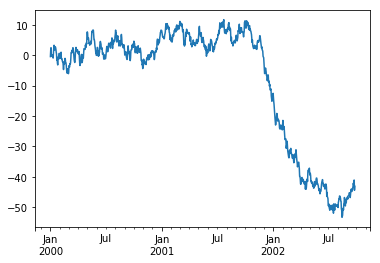

In [84]:
ts = pd.Series(np.random.randn(1000), index=pd.date_range('1/1/2000', periods=1000))
ts.cumsum().plot()

<Figure size 432x288 with 0 Axes>

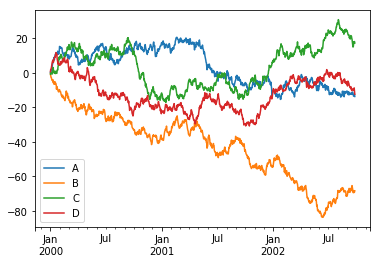

In [86]:
import matplotlib.pyplot as plt

pdf=pd.DataFrame(np.random.randn(1000, 4), index=ts.index,columns=['A', 'B', 'C', 'D'])
pdf = pdf.cumsum()
plt.figure(); pdf.plot(); plt.legend(loc='best')